# Measure Characteristics, Figure, and Table

Lake DT, Civelek Y, Bond AM, Khullar D. Characteristics and financial implications of measures removed from Medicare Advantage star ratings. *JAMA Netw Open*. 2026;9(10):e2640240. doi:[10.1001/jamanetworkopen.2026.40240](https://doi.org/10.1001/jamanetworkopen.2026.40240)

Copyright 2026 Derek T. Lake. Code licensed under the Apache License, Version 2.0 (see `LICENSE` and `NOTICE`). Please cite the article above when using this code or its outputs.

This notebook describes the analytic cohort, places each Star Ratings measure on a common attainment scale, classifies measures as topped out, runs the sensitivity analysis reported in the eMethods, and produces the Figure, the Table, and every number quoted in the Results. It reads the contract-level output of notebook 01, so notebook 01 must be run first. The final section checks each published number.

**Contents**

1. Setup
2. Cohort characteristics
3. Measures and the attainment scale
4. Topped-out classification
5. Sensitivity analysis
6. Rating changes and QBP eligibility
7. Figure
8. Table
9. Verification against the article

## 1. Setup

In [1]:
from decimal import Decimal, ROUND_HALF_UP
import itertools
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_RAW = ROOT / "data" / "raw"
DATA_DERIVED = ROOT / "data" / "derived"
OUTPUTS = ROOT / "outputs"
OUTPUTS.mkdir(exist_ok=True)

MEASURE_DATA_2026 = DATA_RAW / "2026 Star Ratings Data Table - Measure Data (Oct 8 2025).csv"
CPSC_CONTRACT_INFO = DATA_RAW / "CPSC_Contract_Info_2026_05.csv"
CPSC_ENROLLMENT = DATA_RAW / "CPSC_Enrollment_Info_2026_05.csv.zip"

ARTICLE = ("Lake DT, Civelek Y, Bond AM, Khullar D. Characteristics and financial implications of "
           "measures removed from Medicare Advantage star ratings. JAMA Netw Open. "
           "2026;9(10):e2640240. doi:10.1001/jamanetworkopen.2026.40240")

results = pd.read_csv(DATA_DERIVED / "contract_level_results.csv")
weights = pd.read_csv(DATA_DERIVED / "measure_weights.csv")
cohort = results[results["In_Analytic_Cohort"]].copy()

REMOVED = set(weights.loc[weights["Removed"], "Measure"])
IMPROVEMENT = set(weights.loc[weights["Improvement_Measure"], "Measure"])

# Attainment scale (eMethods, Topped-Out Definition). Measures reported as percentages where
# lower values are better are expressed as the percentage of members not readmitted (C18) or
# retained (C29, D03). The complaint measures (C28, D02) are reported per 1000 enrollees; they
# are expressed as the percentage of members without a complaint for display only and are not
# classified.
LOWER_IS_BETTER_PERCENT = {"C18", "C29", "D03"}
RATE_PER_1000 = {"C28", "D02"}

# Topped-out criterion: the bottom-decile contract reaches at least 90 on the attainment
# scale, following the retirement of a beta-blocker quality measure once even bottom-decile
# performers exceeded 90% (Lee TH. N Engl J Med. 2007;357[12]:1175-1177).
FLOOR_PERCENTILE = 10
MARGIN = 10
CEILING = 100

## 2. Cohort characteristics

Plan type, SNP status, and parent organization are taken from the May 2026 Contract/Plan/State/County (CPSC) files, which report enrollment by plan. Plan enrollment is summed within each contract, restricted to MA plan types (coordinated care plans, private fee-for-service, and medical savings account plans). CMS suppresses plan-county cells of 10 or fewer enrollees, so plan-level enrollment is slightly smaller than total contract enrollment; suppressed cells are excluded. A contract's plan type is the MA plan type with the most enrollment, or, for the 5 cohort contracts whose plan cells are all suppressed, the plan type with the most plans. The 5 contracts of other plan types are 3 private fee-for-service contracts and 2 section 1876 cost contracts, which have no MA plans.

In [2]:
info = pd.read_csv(CPSC_CONTRACT_INFO, dtype=str, encoding="cp1252")
info.columns = info.columns.str.strip()
cpsc = pd.read_csv(CPSC_ENROLLMENT, dtype=str, encoding="cp1252")
cpsc.columns = cpsc.columns.str.strip()
cpsc = cpsc.rename(columns={"Contract Number": "Contract ID"})
cpsc["Enrollment"] = pd.to_numeric(cpsc["Enrollment"], errors="coerce")

MA_ORGANIZATION_TYPES = {"Local CCP", "Regional CCP", "PFFS", "MSA"}
PLAN_GROUP = {"HMO/HMOPOS": "HMO", "Local PPO": "PPO", "Regional PPO": "PPO"}

plans = (cpsc.groupby(["Contract ID", "Plan ID"], as_index=False)["Enrollment"].sum()
         .merge(info[["Contract ID", "Plan ID", "Organization Type", "Plan Type", "SNP Plan",
                      "Parent Organization"]], on=["Contract ID", "Plan ID"], how="left"))
plans = plans[plans["Organization Type"].isin(MA_ORGANIZATION_TYPES)].copy()
plans["Plan_Group"] = plans["Plan Type"].map(PLAN_GROUP).fillna("Other")
plans["SNP_Enrollment"] = plans["Enrollment"].where(plans["SNP Plan"].eq("Yes"), 0.0)

mix = (plans.groupby(["Contract ID", "Plan_Group"])["Enrollment"].sum().unstack(fill_value=0.0)
       .reindex(columns=["HMO", "PPO", "Other"], fill_value=0.0))
mix.columns = [f"{c}_Enrollment" for c in mix.columns]
mix["Plan_Enrollment"] = mix.sum(axis=1)
# Plan type is the group with the most enrollment. Where every plan cell of a contract is
# suppressed, the group with the most plans is used instead.
by_enrollment = mix[["HMO_Enrollment", "PPO_Enrollment", "Other_Enrollment"]].idxmax(axis=1).str.replace("_Enrollment", "")
by_plan_count = plans.groupby("Contract ID")["Plan_Group"].agg(lambda s: s.value_counts().idxmax())
mix["Plan_Type"] = by_enrollment.where(mix["Plan_Enrollment"] > 0, by_plan_count)
mix["SNP_Enrollment"] = plans.groupby("Contract ID")["SNP_Enrollment"].sum()
mix["Parent_Organization"] = plans.dropna(subset=["Parent Organization"]).groupby("Contract ID")["Parent Organization"].first()

cohort = cohort.merge(mix, left_on="Contract_ID", right_index=True, how="left")
plan_columns = ["HMO_Enrollment", "PPO_Enrollment", "Other_Enrollment", "Plan_Enrollment", "SNP_Enrollment"]
cohort[plan_columns] = cohort[plan_columns].fillna(0.0)
cohort["Plan_Type"] = cohort["Plan_Type"].fillna("Other")
print(cohort["Plan_Type"].value_counts().to_string())

Plan_Type
HMO      293
PPO      127
Other      5


CMS does not report ownership. Each parent organization is classified explicitly (eMethods, Ownership Classification). `FOR_PROFIT` lists the organizations classified as for-profit in the article: publicly traded companies, privately held investor-owned companies, and one joint venture with a for-profit insurer. All other parent organizations (nonprofit health systems, nonprofit and mutual insurers including most Blue Cross Blue Shield affiliates, public entities, and for-profit subsidiaries wholly or jointly owned by nonprofit or public systems) are classified as nonprofit. The for-profit share is weighted on total contract enrollment. `OTHER_INVESTOR_OWNED` lists smaller privately held parent organizations that are classified as nonprofit in the article; the note after the Table shows the for-profit shares when they are counted as for-profit.

In [3]:
FOR_PROFIT = {
    # Publicly traded
    "UnitedHealth Group, Inc.",
    "Humana Inc.",
    "CVS Health Corporation",
    "Elevance Health, Inc.",
    "Centene Corporation",
    "Molina Healthcare, Inc.",
    "Alignment Healthcare USA, LLC",
    "Clover Health Holdings, Inc.",
    "Universal Health Services, Inc.",
    # Privately held: private equity, venture capital, or other investor owned
    "Devoted Health, Inc.",
    "Imperial Health Plan of California",
    # Joint venture in which one partner is a for-profit insurer
    "Allina Health and Aetna Insurance Holding Company",
}
# Privately held and investor owned, but classified as nonprofit in the article
OTHER_INVESTOR_OWNED = {
    "MHH Healthcare, L.P.",                              # GlobalHealth
    "Lumeris Group Holdings Corporation",                # Essence Healthcare
    "LMC Family Holdings, LLC",                          # Leon Health
    "Clever Care Health Plan, Inc.",
    "Astiva Health Holdings Incorporated",
    "Zing Health Consolidator, Inc",
    "ATRIO Health Plans",
    "DOCTORS HEALTHCARE PLANS, INC.",
    "Athena Healthcare Holdings, LLC",                   # Solis Health Plans
    "Group 1001",                                        # Clear Spring Health
    "Troy Holdings, Inc.",                               # Troy Medicare
    "Gold Kidney Health Plan",
    "General Catalyst Group Management Holdings LP",     # SummaCare
}
cohort["For_Profit"] = cohort["Parent_Organization"].isin(FOR_PROFIT)
cohort[["Contract_ID", "Parent_Organization", "Plan_Type", "HMO_Enrollment", "PPO_Enrollment",
        "Other_Enrollment", "Plan_Enrollment", "SNP_Enrollment"]].to_csv(
    DATA_DERIVED / "cohort_characteristics.csv", index=False)

enrollment = cohort["Enrollment"]
print(f"Contracts: {len(cohort)}; enrollees: {enrollment.sum():,.0f}")
print(f"Median (IQR) enrollment: {enrollment.median():,.0f} "
      f"({enrollment.quantile(0.25):,.0f}-{enrollment.quantile(0.75):,.0f})")
plan_counts = cohort["Plan_Type"].value_counts()
for plan_type in ["HMO", "PPO", "Other"]:
    print(f"{plan_type}: {plan_counts[plan_type]} ({100 * plan_counts[plan_type] / len(cohort):.0f}%)")

Contracts: 425; enrollees: 29,007,964
Median (IQR) enrollment: 15,723 (6,394-50,012)
HMO: 293 (69%)
PPO: 127 (30%)
Other: 5 (1%)


## 3. Measures and the attainment scale

The Measure Data table reports the raw contract-level rate behind each measure star. Each measure's distribution uses every contract that reports the measure in the table. Text entries (for example, "Plan too small to be measured") are treated as missing, as are improvement measures C30 and D04, which have no raw rate. The attainment scale runs from 0 to 100, where 100 is the maximum attainable value of the measure and higher values indicate better performance.

In [4]:
raw = pd.read_csv(MEASURE_DATA_2026, encoding="utf-8-sig", header=None, dtype=str, low_memory=False)
labels, periods = raw.iloc[2].tolist(), raw.iloc[3].tolist()
measure_columns = {}
for i, label in enumerate(labels):
    if isinstance(label, str) and ":" in label and label[:1] in ("C", "D"):
        code_, name = label.split(":", 1)
        if len(code_.strip()) == 3:
            measure_columns[code_.strip()] = (i, name.strip(), periods[i])
measure_data = raw.iloc[4:].copy()


def to_rate(value):
    """Numeric rate, or missing for CMS text entries."""
    if pd.isna(value):
        return np.nan
    text = str(value).strip().replace("%", "").replace(",", "")
    try:
        return float(text)
    except ValueError:
        return np.nan


def to_attainment(measure, rate):
    """Place a raw rate on the 0 to 100 attainment scale (higher is better)."""
    if measure in RATE_PER_1000:
        return 100 - rate / 10        # complaints per 1000 -> percent without a complaint
    if measure in LOWER_IS_BETTER_PERCENT:
        return 100 - rate             # percent readmitted or leaving -> percent not
    return rate


rates = {m: measure_data[i].map(to_rate).dropna()
         for m, (i, _, _) in measure_columns.items() if m not in IMPROVEMENT}
rates = {m: r for m, r in rates.items() if len(r) >= 10}

direct = [m for m in rates if m not in RATE_PER_1000 | LOWER_IS_BETTER_PERCENT]
print(f"Measures with usable raw rates: {len(rates)}")
print(f"  percentages used directly: {len(direct)}")
print(f"  percentages inverted (100 minus rate): {len(LOWER_IS_BETTER_PERCENT & set(rates))}")
print(f"  rates per 1000 enrollees: {len(RATE_PER_1000 & set(rates))}")

Measures with usable raw rates: 43
  percentages used directly: 38
  percentages inverted (100 minus rate): 3
  rates per 1000 enrollees: 2


## 4. Topped-out classification

A measure is topped out when its 10th-percentile (bottom-decile) contract reaches at least 90 on the attainment scale, so that even low-performing contracts are within 10 points of the ceiling (Methods). The 2 complaint measures are not classified: because complaints are rare, every contract sits near the ceiling of the attainment scale, and the criterion would be met regardless of how contracts compare. The Figure shows them with open markers.

In [5]:
def percentile(series, p):
    return series.quantile(p / 100)


classification = pd.DataFrame([{
    "Measure": m,
    "Removed": m in REMOVED,
    "Rate_Based": m in RATE_PER_1000,
    "N_Contracts": len(r),
    "P10_Attainment": percentile(to_attainment(m, r), FLOOR_PERCENTILE),
    "P90_Attainment": percentile(to_attainment(m, r), 90),
} for m, r in rates.items()])
classification["Topped_Out"] = ((classification["P10_Attainment"] >= CEILING - MARGIN)
                                & ~classification["Rate_Based"])

assert len(classification) == 43
assert classification["Removed"].sum() == 13 and (~classification["Removed"]).sum() == 30
assert classification["Rate_Based"].sum() == 2

classification.sort_values(["Removed", "P10_Attainment"], ascending=[False, False]).round(3).to_csv(
    OUTPUTS / "topped_out_classification.csv", index=False)

removed_cls = classification[classification["Removed"] & ~classification["Rate_Based"]]
print("Topped out, removed:", sorted(classification.query("Removed and Topped_Out")["Measure"]))
print("Topped out, retained:", sorted(classification.query("not Removed and Topped_Out")["Measure"]))
print("Bottom-decile attainment among classified removed measures: "
      f"{removed_cls['P10_Attainment'].min():.1f} "
      f"({removed_cls.loc[removed_cls['P10_Attainment'].idxmin(), 'Measure']}) to "
      f"{removed_cls['P10_Attainment'].max():.1f} "
      f"({removed_cls.loc[removed_cls['P10_Attainment'].idxmax(), 'Measure']})")

complaint_min = min(to_attainment(m, rates[m]).min() for m in RATE_PER_1000)
complaint_fold = {m: percentile(rates[m], 90) / percentile(rates[m], 10) for m in sorted(RATE_PER_1000)}
print(f"Complaint measures: lowest attainment {complaint_min:.2f}% complaint free; "
      "90th to 10th percentile ratio of complaint rates "
      + ", ".join(f"{m} {v:.1f}" for m, v in complaint_fold.items()))

Topped out, removed: ['C31', 'C32', 'C33', 'D01', 'D07']
Topped out, retained: []
Bottom-decile attainment among classified removed measures: 55.0 (C07) to 98.0 (D07)
Complaint measures: lowest attainment 99.69% complaint free; 90th to 10th percentile ratio of complaint rates C28 11.7, D02 11.5


The measure reference file combines each measure's CMS name, measurement period, weight, scale, and classification. `docs/measures.md` presents the same information.

In [6]:
def normalize(text):
    """CMS labels use en dashes; replace them with hyphens."""
    return str(text).replace("\u2013", "-").replace("\u2014", "-").strip()


def metric_type(m):
    if m in IMPROVEMENT:
        return "Improvement score (no raw rate)"
    return "Rate per 1000 enrollees" if m in RATE_PER_1000 else "Percentage"


def transform(m):
    if m in IMPROVEMENT:
        return "Not applicable"
    if m in RATE_PER_1000:
        return "100 - rate/10 (display only)"
    return "100 - rate" if m in LOWER_IS_BETTER_PERCENT else "rate"


reference = weights.copy()
reference["CMS_Name"] = reference["Measure"].map(lambda m: normalize(measure_columns[m][1]))
reference["Measurement_Period"] = reference["Measure"].map(lambda m: normalize(measure_columns[m][2]))
reference["Metric"] = reference["Measure"].map(metric_type)
reference["Higher_Is_Better"] = ~reference["Measure"].isin(LOWER_IS_BETTER_PERCENT | RATE_PER_1000)
reference["Attainment_Transform"] = reference["Measure"].map(transform)
reference = reference.merge(classification[["Measure", "N_Contracts", "P10_Attainment",
                                            "P90_Attainment", "Topped_Out"]],
                            on="Measure", how="left")
reference.loc[reference["Measure"].isin(RATE_PER_1000), "Topped_Out"] = np.nan
reference = reference[["Measure", "CMS_Name", "Part", "Removed", "Improvement_Measure", "Weight",
                       "Metric", "Higher_Is_Better", "Attainment_Transform", "Measurement_Period",
                       "N_Contracts", "P10_Attainment", "P90_Attainment", "Topped_Out"]]
reference.round(3).to_csv(DATA_DERIVED / "measure_reference.csv", index=False)
reference.head()

,Measure,CMS_Name,Part,Removed,Improvement_Measure,Weight,Metric,Higher_Is_Better,Attainment_Transform,Measurement_Period,N_Contracts,P10_Attainment,P90_Attainment,Topped_Out
0,C01,Breast Cancer Screening,C,False,False,1,Percentage,True,rate,01/01/2024 - 12/31/2024,499.0,61.0,84.0,False
1,C02,Colorectal Cancer Screening,C,False,False,1,Percentage,True,rate,01/01/2024 - 12/31/2024,544.0,59.0,82.0,False
2,C03,Annual Flu Vaccine,C,False,False,1,Percentage,True,rate,03/2025 - 05/2025,497.0,56.0,76.4,False
3,C04,Improving or Maintaining Physical Health,C,False,False,1,Percentage,True,rate,07/17/2024 - 11/01/2024,295.0,67.0,75.0,False
4,C05,Improving or Maintaining Mental Health,C,False,False,1,Percentage,True,rate,07/17/2024 - 11/01/2024,294.0,80.0,88.0,False


## 5. Sensitivity analysis

The eMethods (Topped-Out Definition) report the classification under percentile floors of 5, 10, and 15 crossed with margins of 5, 10, and 15 points. Counts of removed measures exclude the 2 complaint measures, which are not classified; a second column includes them for reference.

In [7]:
rows = []
for floor, margin in itertools.product([5, 10, 15], [5, 10, 15]):
    qualify = {m for m, r in rates.items()
               if percentile(to_attainment(m, r), floor) >= CEILING - margin}
    rows.append({
        "Floor_Percentile": floor,
        "Margin": margin,
        "Removed_Classified": len((qualify & REMOVED) - RATE_PER_1000),
        "Removed_Including_Complaints": len(qualify & REMOVED),
        "Retained": len(qualify - REMOVED),
        "Retained_Measures": ", ".join(sorted(qualify - REMOVED)),
    })
sensitivity = pd.DataFrame(rows)
sensitivity.to_csv(OUTPUTS / "sensitivity_thresholds.csv", index=False)
sensitivity

,Floor_Percentile,Margin,Removed_Classified,Removed_Including_Complaints,Retained,Retained_Measures
0,5,5,0,2,0,
1,5,10,1,3,0,
2,5,15,6,8,3,"C18, D06, D09"
3,10,5,1,3,0,
4,10,10,5,7,0,
5,10,15,6,8,7,"C08, C09, C18, C27, D06, D09, D10"
6,15,5,3,5,0,
7,15,10,5,7,1,C08
8,15,15,6,8,7,"C08, C09, C18, C27, D06, D09, D10"


## 6. Rating changes and QBP eligibility

These values appear in the Results text. QBP eligibility requires an overall rating of at least 4.0 stars. Dollar values are annual 2026 amounts from notebook 01.

In [8]:
change = cohort["Rating_Change"]
qbp = cohort.groupby("QBP_Change")
text_values = {
    "Contracts": len(cohort),
    "Enrollees": cohort["Enrollment"].sum(),
    "Median enrollment": cohort["Enrollment"].median(),
    "Enrollment 25th percentile": cohort["Enrollment"].quantile(0.25),
    "Enrollment 75th percentile": cohort["Enrollment"].quantile(0.75),
    "HMO contracts": plan_counts["HMO"],
    "PPO contracts": plan_counts["PPO"],
    "Other plan type contracts": plan_counts["Other"],
    "Removed measures topped out": int(classification.query("Removed and Topped_Out").shape[0]),
    "Retained measures topped out": int(classification.query("not Removed and Topped_Out").shape[0]),
    "Rating declines, %": 100 * (change < 0).mean(),
    "Rating unchanged, %": 100 * (change == 0).mean(),
    "Rating increases, %": 100 * (change > 0).mean(),
    "Baseline mean rating": cohort["Baseline_Overall"].mean(),
    "Projected mean rating": cohort["Projected_Overall"].mean(),
    "Baseline median rating": cohort["Baseline_Overall"].median(),
    "Baseline rating 25th percentile": cohort["Baseline_Overall"].quantile(0.25),
    "Baseline rating 75th percentile": cohort["Baseline_Overall"].quantile(0.75),
    "Projected median rating": cohort["Projected_Overall"].median(),
    "Projected rating 25th percentile": cohort["Projected_Overall"].quantile(0.25),
    "Projected rating 75th percentile": cohort["Projected_Overall"].quantile(0.75),
    "Contracts losing QBP eligibility": int(qbp.size()["Lose"]),
    "Enrollees in contracts losing QBP eligibility": qbp["Enrollment"].sum()["Lose"],
    "Contracts gaining QBP eligibility": int(qbp.size()["Gain"]),
    "Enrollees in contracts gaining QBP eligibility": qbp["Enrollment"].sum()["Gain"],
    "Baseline QBP pool, $ millions": cohort["Baseline_QBP"].sum() / 1e6,
    "Net QBP change, $ millions": cohort["Net_QBP_Change"].sum() / 1e6,
    "Net QBP change, % of baseline pool": 100 * cohort["Net_QBP_Change"].sum() / cohort["Baseline_QBP"].sum(),
}
text_values = pd.Series(text_values, name="Value")
text_values.to_frame().to_csv(OUTPUTS / "results_text_values.csv", index_label="Quantity")
text_values.round(3).to_frame()

,Value
Contracts,4.250000e+02
Enrollees,2.900796e+07
Median enrollment,1.572300e+04
Enrollment 25th percentile,6.394000e+03
Enrollment 75th percentile,5.001200e+04
HMO contracts,2.930000e+02
PPO contracts,1.270000e+02
Other plan type contracts,5.000000e+00
Removed measures topped out,5.000000e+00
Retained measures topped out,0.000000e+00


## 7. Figure

Each row is one of the 43 measures, ordered by bottom-decile attainment. The solid dot marks the 10th-percentile contract, the small dot the 90th-percentile contract, and the bar the range between them. Orange marks removed measures and blue retained measures. The dotted line at 90 bounds the topped-out region. Open markers show the 2 complaint measures, which are not classified. Measure labels follow the published Figure. The vector PDF embeds TrueType fonts (`pdf.fonttype` 42) so text remains editable, and its metadata carries the article citation.

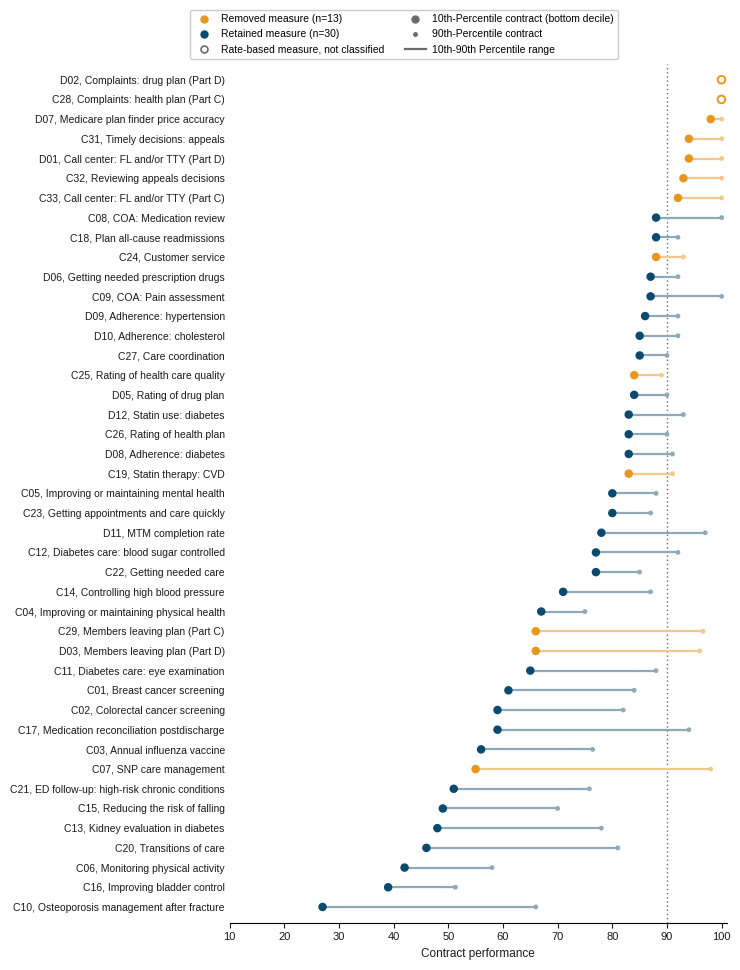

In [9]:
FIGURE_LABELS = {
    "C01": "Breast cancer screening", "C02": "Colorectal cancer screening",
    "C03": "Annual influenza vaccine", "C04": "Improving or maintaining physical health",
    "C05": "Improving or maintaining mental health", "C06": "Monitoring physical activity",
    "C07": "SNP care management", "C08": "COA: Medication review", "C09": "COA: Pain assessment",
    "C10": "Osteoporosis management after fracture", "C11": "Diabetes care: eye examination",
    "C12": "Diabetes care: blood sugar controlled", "C13": "Kidney evaluation in diabetes",
    "C14": "Controlling high blood pressure", "C15": "Reducing the risk of falling",
    "C16": "Improving bladder control", "C17": "Medication reconciliation postdischarge",
    "C18": "Plan all-cause readmissions", "C19": "Statin therapy: CVD",
    "C20": "Transitions of care", "C21": "ED follow-up: high-risk chronic conditions",
    "C22": "Getting needed care", "C23": "Getting appointments and care quickly",
    "C24": "Customer service", "C25": "Rating of health care quality",
    "C26": "Rating of health plan", "C27": "Care coordination",
    "C28": "Complaints: health plan (Part C)", "C29": "Members leaving plan (Part C)",
    "C31": "Timely decisions: appeals", "C32": "Reviewing appeals decisions",
    "C33": "Call center: FL and/or TTY (Part C)", "D01": "Call center: FL and/or TTY (Part D)",
    "D02": "Complaints: drug plan (Part D)", "D03": "Members leaving plan (Part D)",
    "D05": "Rating of drug plan", "D06": "Getting needed prescription drugs",
    "D07": "Medicare plan finder price accuracy", "D08": "Adherence: diabetes",
    "D09": "Adherence: hypertension", "D10": "Adherence: cholesterol",
    "D11": "MTM completion rate", "D12": "Statin use: diabetes",
}
REMOVED_COLOR, RETAINED_COLOR = "#E8961E", "#0B4A6F"
REMOVED_RANGE, RETAINED_RANGE = "#F3C98B", "#8FA9B8"
INK, MUTED = "#1A1A1A", "#6B6B6B"

plt.rcParams.update({"font.family": "sans-serif",
                     "font.sans-serif": ["Arial", "Liberation Sans", "Helvetica", "DejaVu Sans"],
                     "pdf.fonttype": 42, "ps.fonttype": 42, "axes.linewidth": 0.8})

# Rows run top to bottom in the order of the published Figure: descending bottom-decile
# attainment, with ties in the published order.
PUBLISHED_ORDER = [
    "D02", "C28", "D07", "C31", "D01", "C32", "C33", "C08", "C18", "C24", "D06", "C09", "D09",
    "D10", "C27", "C25", "D05", "D12", "C26", "D08", "C19", "C05", "C23", "D11", "C12", "C22",
    "C14", "C04", "C29", "D03", "C11", "C01", "C02", "C17", "C03", "C07", "C21", "C15", "C13",
    "C20", "C06", "C16", "C10",
]
plot = classification.set_index("Measure").loc[PUBLISHED_ORDER[::-1]].reset_index()
assert plot["P10_Attainment"].is_monotonic_increasing
y = np.arange(len(plot))
removed = plot["Removed"].to_numpy()
rate_based = plot["Rate_Based"].to_numpy()
point_color = np.where(removed, REMOVED_COLOR, RETAINED_COLOR)
range_color = np.where(removed, REMOVED_RANGE, RETAINED_RANGE)

fig, ax = plt.subplots(figsize=(7.5, 9.8))
ax.axvline(CEILING - MARGIN, color=MUTED, linestyle=(0, (1, 2)), linewidth=1.0, zorder=1)
ax.hlines(y, plot["P10_Attainment"], plot["P90_Attainment"], colors=range_color,
          linewidth=1.6, zorder=2)
ax.scatter(plot["P90_Attainment"], y, s=6, c=range_color, zorder=3)
ax.scatter(plot.loc[~rate_based, "P10_Attainment"], y[~rate_based], s=26,
           c=point_color[~rate_based], zorder=4)
ax.scatter(plot.loc[rate_based, "P10_Attainment"], y[rate_based], s=30, facecolors="white",
           edgecolors=point_color[rate_based], linewidths=1.4, zorder=5)

ax.set_yticks(y)
ax.set_yticklabels([f"{m}, {FIGURE_LABELS[m]}" for m in plot["Measure"]], fontsize=7.5, color=INK)
ax.set_ylim(-0.8, len(plot) - 0.2)
ax.set_xlim(10, 101)
ax.set_xticks(range(10, 101, 10))
ax.set_xlabel("Contract performance", fontsize=8.5, color=INK)
ax.tick_params(axis="x", labelsize=8, colors=INK)
ax.tick_params(axis="y", length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)

legend_items = [
    Line2D([0], [0], marker="o", linestyle="", markersize=5, markerfacecolor=REMOVED_COLOR,
           markeredgecolor=REMOVED_COLOR, label=f"Removed measure (n={int(removed.sum())})"),
    Line2D([0], [0], marker="o", linestyle="", markersize=5, markerfacecolor=RETAINED_COLOR,
           markeredgecolor=RETAINED_COLOR, label=f"Retained measure (n={int((~removed).sum())})"),
    Line2D([0], [0], marker="o", linestyle="", markersize=5, markerfacecolor="white",
           markeredgecolor=MUTED, markeredgewidth=1.2, label="Rate-based measure, not classified"),
    Line2D([0], [0], marker="o", linestyle="", markersize=5, markerfacecolor=MUTED,
           markeredgecolor=MUTED, label="10th-Percentile contract (bottom decile)"),
    Line2D([0], [0], marker="o", linestyle="", markersize=2.5, markerfacecolor=MUTED,
           markeredgecolor=MUTED, label="90th-Percentile contract"),
    Line2D([0], [0], color=MUTED, linewidth=1.6, label="10th-90th Percentile range"),
]
ax.legend(handles=legend_items, loc="lower center", bbox_to_anchor=(0.35, 1.0), ncol=2,
          frameon=True, edgecolor="#BFBFBF", fontsize=7.5, columnspacing=2.0,
          handletextpad=0.6, labelspacing=0.5)
fig.tight_layout()

PDF_METADATA = {"Title": "Dot plot of contract performance on Star Rating measures by removal status",
                "Author": "Derek T. Lake", "Subject": ARTICLE,
                "Keywords": "Medicare Advantage; Star Ratings; quality bonus payments",
                "CreationDate": None}
fig.savefig(OUTPUTS / "figure_dot_plot.pdf", bbox_inches="tight", metadata=PDF_METADATA)
fig.savefig(OUTPUTS / "figure_dot_plot.png", dpi=300, bbox_inches="tight",
            metadata={"Title": PDF_METADATA["Title"], "Author": "Derek T. Lake",
                      "Description": ARTICLE})
plt.show()

## 8. Table

QBP eligibility transitions and the characteristics of contracts in each group. HMO and SNP percentages are weighted on plan-level CPSC enrollment; the for-profit percentage is weighted on total contract enrollment. Net QBP change is expressed relative to the baseline QBP pool of the analytic cohort. The numeric table keeps full precision. The formatted table rounds half up, as the article does; Python's default formatting sends exact halves to the nearest even value.

In [10]:
GROUPS = ["Lose", "Gain", "Retain", "Never"]
pool = cohort["Baseline_QBP"].sum()


def group_row(g):
    return pd.Series({
        "Contracts": len(g),
        "Enrollees": g["Enrollment"].sum(),
        "Enrollees_Pct": 100 * g["Enrollment"].sum() / cohort["Enrollment"].sum(),
        "Median_Enrollment": g["Enrollment"].median(),
        "Enrollment_P25": g["Enrollment"].quantile(0.25),
        "Enrollment_P75": g["Enrollment"].quantile(0.75),
        "HMO_Pct": 100 * g["HMO_Enrollment"].sum() / g["Plan_Enrollment"].sum(),
        "SNP_Pct": 100 * g["SNP_Enrollment"].sum() / g["Plan_Enrollment"].sum(),
        "For_Profit_Pct": 100 * g.loc[g["For_Profit"], "Enrollment"].sum() / g["Enrollment"].sum(),
        "Baseline_QBP_Millions": g["Baseline_QBP"].sum() / 1e6,
        "Net_QBP_Change_Millions": g["Net_QBP_Change"].sum() / 1e6,
        "Net_QBP_Change_Pct": 100 * g["Net_QBP_Change"].sum() / pool,
    })


table = pd.DataFrame({grp: group_row(cohort[cohort["QBP_Change"] == grp]) for grp in GROUPS}).T
table.loc["Total"] = group_row(cohort)
for col in ["Median_Enrollment", "Enrollment_P25", "Enrollment_P75", "HMO_Pct", "SNP_Pct", "For_Profit_Pct"]:
    table.loc["Total", col] = np.nan
table.index.name = "QBP_Eligibility_Change"
table.to_csv(OUTPUTS / "table_qbp_transitions.csv")


def half_up(x, places=0):
    return Decimal(repr(float(x))).quantize(Decimal(1).scaleb(-places), rounding=ROUND_HALF_UP)


def fmt(x, places=0):
    """JAMA style: half-up rounding; thin grouping only for values of 10 000 or more."""
    value = half_up(x, places)
    text = f"{abs(value):,.{places}f}" if abs(value) >= 10_000 else f"{abs(value):.{places}f}"
    return ("-" if value < 0 else "") + text.replace(",", " ")


formatted = pd.DataFrame(index=table.index)
formatted["Contracts, No."] = table["Contracts"].map(fmt)
formatted["Enrollees, No. (%)"] = [f"{fmt(n)} ({fmt(p, 1)})" for n, p in zip(table["Enrollees"], table["Enrollees_Pct"])]
formatted["Median (IQR) enrollment"] = [
    "NA" if pd.isna(m) else f"{fmt(m)} ({fmt(a)}-{fmt(b)})"
    for m, a, b in zip(table["Median_Enrollment"], table["Enrollment_P25"], table["Enrollment_P75"])]
for col, src in [("HMO, %", "HMO_Pct"), ("SNP, %", "SNP_Pct"), ("For profit, %", "For_Profit_Pct")]:
    formatted[col] = ["NA" if pd.isna(v) else fmt(v, 1) for v in table[src]]
formatted["Baseline QBP, $ (millions)"] = table["Baseline_QBP_Millions"].map(fmt)
formatted["Net QBP change, $ (millions) (%)"] = [
    "0" if half_up(n) == 0 else f"{fmt(n)} ({fmt(p, 1)})"
    for n, p in zip(table["Net_QBP_Change_Millions"], table["Net_QBP_Change_Pct"])]
formatted.to_csv(OUTPUTS / "table_qbp_transitions_formatted.csv")

with open(OUTPUTS / "table_qbp_transitions_formatted.md", "w") as f:
    f.write("Table. Estimated Changes in QBP Eligibility and Characteristics of Affected "
            "Contracts After Measure Removal\n\n")
    f.write("| QBP eligibility change | " + " | ".join(formatted.columns) + " |\n")
    f.write("|---" * (len(formatted.columns) + 1) + "|\n")
    for idx, row in formatted.iterrows():
        f.write(f"| {idx} | " + " | ".join(row) + " |\n")
    f.write(f"\nSource: {ARTICLE}\n")
formatted

,"Contracts, No.","Enrollees, No. (%)",Median (IQR) enrollment,"HMO, %","SNP, %","For profit, %","Baseline QBP, $ (millions)","Net QBP change, $ (millions) (%)"
QBP_Eligibility_Change,,,,,,,,
Lose,33,2 587 448 (8.9),22 641 (11 416-55 777),94.5,27.2,76.5,2271,-2271 (-15.1)
Gain,6,239 560 (0.8),28 985 (11 335-49 486),32.4,12.6,70.5,0,178 (1.2)
Retain,113,15 671 651 (54.0),40 177 (14 061-113 669),55.0,15.7,53.3,12 786,0
Never,273,10 509 305 (36.2),11 115 (4265-30 138),53.6,25.2,78.3,0,0
Total,425,29 007 964 (100.0),NA,NA,NA,NA,15 057,-2093 (-13.9)


Note on ownership. Counting the parent organizations in `OTHER_INVESTOR_OWNED` as for-profit changes only the for-profit column of the Table. The shares under that classification are shown below; every other value is unaffected.

In [11]:
investor_owned = cohort["Parent_Organization"].isin(FOR_PROFIT | OTHER_INVESTOR_OWNED)
alternative = pd.Series({grp: fmt(100 * cohort.loc[(cohort["QBP_Change"] == grp) & investor_owned, "Enrollment"].sum()
                                  / cohort.loc[cohort["QBP_Change"] == grp, "Enrollment"].sum(), 1)
                         for grp in GROUPS}, name="For profit, % (including OTHER_INVESTOR_OWNED)")
pd.DataFrame({"For profit, % (article)": formatted.loc[GROUPS, "For profit, %"], alternative.name: alternative})

,"For profit, % (article)","For profit, % (including OTHER_INVESTOR_OWNED)"
Lose,76.5,77.2
Gain,70.5,70.5
Retain,53.3,56.5
Never,78.3,80.3


## 9. Verification against the article

Each assertion restates a number printed in the Research Letter, its Table, or its eMethods. The notebook stops at the first number that does not reproduce.

In [12]:
ARTICLE_TABLE = {
    "Lose":   ["33", "2 587 448 (8.9)", "22 641 (11 416-55 777)", "94.5", "27.2", "76.5", "2271", "-2271 (-15.1)"],
    "Gain":   ["6", "239 560 (0.8)", "28 985 (11 335-49 486)", "32.4", "12.6", "70.5", "0", "178 (1.2)"],
    "Retain": ["113", "15 671 651 (54.0)", "40 177 (14 061-113 669)", "55.0", "15.7", "53.3", "12 786", "0"],
    "Never":  ["273", "10 509 305 (36.2)", "11 115 (4265-30 138)", "53.6", "25.2", "78.3", "0", "0"],
    "Total":  ["425", "29 007 964 (100.0)", "NA", "NA", "NA", "NA", "15 057", "-2093 (-13.9)"],
}
checks = []


def check(label, condition):
    checks.append(label)
    assert condition, f"Does not reproduce: {label}"


reasons = results["Exclusion_Reason"].value_counts()
check("769 contracts in the 2026 Star Ratings", len(results) == 769)
check("269 without an overall rating", reasons["No overall rating"] == 269)
check("64 disaster affected", reasons["Disaster affected"] == 64)
check("6 below the minimum measure threshold", reasons["Below minimum measure threshold after removal"] == 6)
check("5 without linkable enrollment", reasons["No linkable May 2026 enrollment"] == 5)
check("425 contracts in the analytic cohort", len(cohort) == 425)
check("29 007 964 enrollees (29.0 million)", cohort["Enrollment"].sum() == 29_007_964)
check("Median (IQR) enrollment 15 723 (6394-50 012)",
      (fmt(enrollment.median()), fmt(enrollment.quantile(0.25)), fmt(enrollment.quantile(0.75)))
      == ("15 723", "6394", "50 012"))
check("293 (69%) HMO, 127 (30%) PPO, 5 (1%) other",
      [(plan_counts[p], round(100 * plan_counts[p] / len(cohort))) for p in ["HMO", "PPO", "Other"]]
      == [(293, 69), (127, 30), (5, 1)])

non_disaster = results[(results["Exclusion_Reason"] != "No overall rating")
                       & (results["Exclusion_Reason"] != "Disaster affected")]
mismatch = non_disaster[~non_disaster["Replication_Match"].astype(bool)]
check("5 of 436 non-disaster contracts (1.1%) differ from CMS",
      len(non_disaster) == 436 and len(mismatch) == 5 and round(100 * 5 / 436, 1) == 1.1)
check("each mismatch differs by exactly 0.5 stars",
      ((mismatch["Baseline_Overall"] - mismatch["CMS_Overall"]).abs() == 0.5).all())

check("43 measures with usable raw rates", len(rates) == 43)
check("38 percentages used directly", len(direct) == 38)
check("3 inverted percentages: C18, C29, D03", LOWER_IS_BETTER_PERCENT <= set(rates))
check("2 rates per 1000 enrollees: C28, D02", RATE_PER_1000 <= set(rates))
check("improvement measures C30 and D04 excluded", not (IMPROVEMENT & set(rates)))
check("13 removed components", REMOVED == {"C07", "C19", "C24", "C25", "C28", "C29", "C31", "C32",
                                           "C33", "D01", "D02", "D03", "D07"})
nonimprovement = weights[~weights["Improvement_Measure"]]
check("CMS weights range from 1 to 3", set(nonimprovement["Weight"]) == {1, 2, 3})
check("10 of 13 removed components carry a weight of 2",
      (weights.loc[weights["Removed"], "Weight"] == 2).sum() == 10)

topped_removed = classification.query("Removed and Topped_Out")
check("5 of 13 removed components (38%) topped out",
      len(topped_removed) == 5 and round(100 * 5 / 13) == 38)
check("0 of 30 retained measures topped out", classification.query("not Removed and Topped_Out").empty)
check("bottom-decile attainment of classified removed measures ranges from 55 (C07) to 98 (D07)",
      half_up(removed_cls["P10_Attainment"].min()) == 55
      and removed_cls.loc[removed_cls["P10_Attainment"].idxmin(), "Measure"] == "C07"
      and half_up(removed_cls["P10_Attainment"].max()) == 98
      and removed_cls.loc[removed_cls["P10_Attainment"].idxmax(), "Measure"] == "D07")
check("every contract at least 99.6% complaint free", complaint_min >= 99.6)
check("complaint rates vary approximately 12-fold between deciles",
      all(round(v) == 12 for v in complaint_fold.values()))

grid = sensitivity.set_index(["Floor_Percentile", "Margin"])
check("10-point margin: no retained measure topped out at the 5th or 10th percentile floor",
      grid.loc[(5, 10), "Retained"] == 0 and grid.loc[(10, 10), "Retained"] == 0)
check("10-point margin: a 15th percentile floor admits one retained measure",
      grid.loc[(15, 10), "Retained"] == 1)
check("15-point margin no longer separates removed from retained measures",
      all(grid.loc[(f, 15), "Retained"] > 0 for f in [5, 10, 15]))

check("ratings decline for 35.1%, unchanged for 62.6%, increase for 2.4%",
      [round(text_values[k], 1) for k in ["Rating declines, %", "Rating unchanged, %", "Rating increases, %"]]
      == [35.1, 62.6, 2.4])
check("mean rating falls from 3.58 to 3.41",
      (round(text_values["Baseline mean rating"], 2), round(text_values["Projected mean rating"], 2)) == (3.58, 3.41))
check("median (IQR) rating 3.5 (3.0-4.0) at baseline and after removal",
      [text_values[k] for k in ["Baseline median rating", "Baseline rating 25th percentile",
                                "Baseline rating 75th percentile", "Projected median rating",
                                "Projected rating 25th percentile", "Projected rating 75th percentile"]]
      == [3.5, 3.0, 4.0, 3.5, 3.0, 4.0])
check("33 contracts covering 2 587 448 enrollees (8.9%) lose eligibility",
      text_values["Contracts losing QBP eligibility"] == 33
      and text_values["Enrollees in contracts losing QBP eligibility"] == 2_587_448
      and round(100 * 2_587_448 / 29_007_964, 1) == 8.9)
check("6 contracts covering 239 560 enrollees (0.8%) gain eligibility",
      text_values["Contracts gaining QBP eligibility"] == 6
      and text_values["Enrollees in contracts gaining QBP eligibility"] == 239_560
      and round(100 * 239_560 / 29_007_964, 1) == 0.8)
check("net QBP reduction of $2.09 billion (-2093 million)",
      round(text_values["Net QBP change, $ millions"] / 1000, 2) == -2.09
      and half_up(text_values["Net QBP change, $ millions"]) == -2093)
check("13.9% of the $15 057 million ($15.1 billion) baseline pool",
      round(text_values["Net QBP change, % of baseline pool"], 1) == -13.9
      and half_up(text_values["Baseline QBP pool, $ millions"]) == 15057)
for group, row in ARTICLE_TABLE.items():
    check(f"Table row {group} matches the article", list(formatted.loc[group]) == row)

check("software versions match the published statement",
      (pd.__version__, np.__version__, matplotlib.__version__) == ("2.2.3", "2.2.4", "3.10.1"))

print(f"All {len(checks)} values reported in the article reproduced:")
for label in checks:
    print(f"  {label}")

All 40 values reported in the article reproduced:
  769 contracts in the 2026 Star Ratings
  269 without an overall rating
  64 disaster affected
  6 below the minimum measure threshold
  5 without linkable enrollment
  425 contracts in the analytic cohort
  29 007 964 enrollees (29.0 million)
  Median (IQR) enrollment 15 723 (6394-50 012)
  293 (69%) HMO, 127 (30%) PPO, 5 (1%) other
  5 of 436 non-disaster contracts (1.1%) differ from CMS
  each mismatch differs by exactly 0.5 stars
  43 measures with usable raw rates
  38 percentages used directly
  3 inverted percentages: C18, C29, D03
  2 rates per 1000 enrollees: C28, D02
  improvement measures C30 and D04 excluded
  13 removed components
  CMS weights range from 1 to 3
  10 of 13 removed components carry a weight of 2
  5 of 13 removed components (38%) topped out
  0 of 30 retained measures topped out
  bottom-decile attainment of classified removed measures ranges from 55 (C07) to 98 (D07)
  every contract at least 99.6% complai